In [10]:

import sys
from pathlib import Path

import nibabel as nib
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

PATIENT_ID = "P2658"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load ground-truth MRI
# --------------------------------------------------

gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

# --------------------------------------------------
# Load TTA mean prediction
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(
    pred_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load normalized uncertainty
# --------------------------------------------------

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(
    unc_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load head/body-region mask
# --------------------------------------------------

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(
    mask_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Verify shape and spatial alignment
# --------------------------------------------------

assert gt.shape == pred.shape == unc.shape == mask.shape, (
    "Volume shapes do not match."
)

assert np.allclose(gt_img.affine, pred_img.affine), (
    "Ground-truth MRI and prediction affine mismatch."
)

assert np.allclose(gt_img.affine, unc_img.affine), (
    "Ground-truth MRI and uncertainty affine mismatch."
)

assert np.allclose(gt_img.affine, mask_img.affine), (
    "Ground-truth MRI and mask affine mismatch."
)

print("All volume shapes and affines are aligned.")

# --------------------------------------------------
# Apply official MRI normalization
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_mri

gt = normalise_mri(gt, mask)

# --------------------------------------------------
# Calculate actual reconstruction error
# --------------------------------------------------

error = np.abs(pred - gt)

# --------------------------------------------------
# Select valid voxels inside the supplied mask
# --------------------------------------------------

valid = (
    (mask > 0)
    & np.isfinite(gt)
    & np.isfinite(pred)
    & np.isfinite(error)
    & np.isfinite(unc)
)

actual_error = error[valid]
predicted_uncertainty = unc[valid]

if len(actual_error) < 2:
    raise ValueError("Not enough valid voxels for evaluation.")

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

correlation, p_value = spearmanr(
    predicted_uncertainty,
    actual_error
)

masked_mae = float(actual_error.mean())
mean_uncertainty = float(predicted_uncertainty.mean())

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\n========== UNCERTAINTY VALIDATION ==========")

print("Patient:", PATIENT_ID)
print("Volume shape:", gt.shape)
print("Evaluated voxels:", len(actual_error))

print("Masked MAE:", masked_mae)
print("Mean uncertainty:", mean_uncertainty)

print("Spearman correlation:", float(correlation))
print("P-value:", float(p_value))

print("\nInterpretation:")

if not np.isfinite(correlation):
    print("Correlation is undefined. Check for constant values.")
elif correlation > 0.3:
    print("Positive relationship: higher uncertainty tends to accompany higher error.")
elif correlation > 0:
    print("Weak positive relationship: uncertainty ranking may need improvement.")
else:
    print("No positive relationship detected. Investigate uncertainty estimation.")

print("\nValidation completed successfully.")


All volume shapes and affines are aligned.

========== UNCERTAINTY VALIDATION ==========
Patient: P2658
Volume shape: (192, 224, 192)
Evaluated voxels: 4374578
Masked MAE: 0.10907888412475586
Mean uncertainty: 0.12039189785718918
Spearman correlation: 0.5798820536383986
P-value: 0.0

Interpretation:
Positive relationship: higher uncertainty tends to accompany higher error.

Validation completed successfully.


In [9]:

import sys
from pathlib import Path

import nibabel as nib
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

PATIENT_ID = "P6123"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load ground-truth MRI
# --------------------------------------------------

gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

# --------------------------------------------------
# Load TTA mean prediction
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(
    pred_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load normalized uncertainty
# --------------------------------------------------

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(
    unc_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load head/body-region mask
# --------------------------------------------------

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(
    mask_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Verify shape and spatial alignment
# --------------------------------------------------

assert gt.shape == pred.shape == unc.shape == mask.shape, (
    "Volume shapes do not match."
)

assert np.allclose(gt_img.affine, pred_img.affine), (
    "Ground-truth MRI and prediction affine mismatch."
)

assert np.allclose(gt_img.affine, unc_img.affine), (
    "Ground-truth MRI and uncertainty affine mismatch."
)

assert np.allclose(gt_img.affine, mask_img.affine), (
    "Ground-truth MRI and mask affine mismatch."
)

print("All volume shapes and affines are aligned.")

# --------------------------------------------------
# Apply official MRI normalization
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_mri

gt = normalise_mri(gt, mask)

# --------------------------------------------------
# Calculate actual reconstruction error
# --------------------------------------------------

error = np.abs(pred - gt)

# --------------------------------------------------
# Select valid voxels inside the supplied mask
# --------------------------------------------------

valid = (
    (mask > 0)
    & np.isfinite(gt)
    & np.isfinite(pred)
    & np.isfinite(error)
    & np.isfinite(unc)
)

actual_error = error[valid]
predicted_uncertainty = unc[valid]

if len(actual_error) < 2:
    raise ValueError("Not enough valid voxels for evaluation.")

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

correlation, p_value = spearmanr(
    predicted_uncertainty,
    actual_error
)

masked_mae = float(actual_error.mean())
mean_uncertainty = float(predicted_uncertainty.mean())

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\n========== UNCERTAINTY VALIDATION ==========")

print("Patient:", PATIENT_ID)
print("Volume shape:", gt.shape)
print("Evaluated voxels:", len(actual_error))

print("Masked MAE:", masked_mae)
print("Mean uncertainty:", mean_uncertainty)

print("Spearman correlation:", float(correlation))
print("P-value:", float(p_value))

print("\nInterpretation:")

if not np.isfinite(correlation):
    print("Correlation is undefined. Check for constant values.")
elif correlation > 0.3:
    print("Positive relationship: higher uncertainty tends to accompany higher error.")
elif correlation > 0:
    print("Weak positive relationship: uncertainty ranking may need improvement.")
else:
    print("No positive relationship detected. Investigate uncertainty estimation.")

print("\nValidation completed successfully.")


All volume shapes and affines are aligned.

========== UNCERTAINTY VALIDATION ==========
Patient: P6123
Volume shape: (192, 224, 192)
Evaluated voxels: 5052857
Masked MAE: 0.11643092334270477
Mean uncertainty: 0.11863741278648376
Spearman correlation: 0.5673815726283632
P-value: 0.0

Interpretation:
Positive relationship: higher uncertainty tends to accompany higher error.

Validation completed successfully.


In [8]:

import sys
from pathlib import Path

import nibabel as nib
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

PATIENT_ID = "P7363"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load ground-truth MRI
# --------------------------------------------------

gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

# --------------------------------------------------
# Load TTA mean prediction
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(
    pred_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load normalized uncertainty
# --------------------------------------------------

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(
    unc_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load head/body-region mask
# --------------------------------------------------

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(
    mask_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Verify shape and spatial alignment
# --------------------------------------------------

assert gt.shape == pred.shape == unc.shape == mask.shape, (
    "Volume shapes do not match."
)

assert np.allclose(gt_img.affine, pred_img.affine), (
    "Ground-truth MRI and prediction affine mismatch."
)

assert np.allclose(gt_img.affine, unc_img.affine), (
    "Ground-truth MRI and uncertainty affine mismatch."
)

assert np.allclose(gt_img.affine, mask_img.affine), (
    "Ground-truth MRI and mask affine mismatch."
)

print("All volume shapes and affines are aligned.")

# --------------------------------------------------
# Apply official MRI normalization
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_mri

gt = normalise_mri(gt, mask)

# --------------------------------------------------
# Calculate actual reconstruction error
# --------------------------------------------------

error = np.abs(pred - gt)

# --------------------------------------------------
# Select valid voxels inside the supplied mask
# --------------------------------------------------

valid = (
    (mask > 0)
    & np.isfinite(gt)
    & np.isfinite(pred)
    & np.isfinite(error)
    & np.isfinite(unc)
)

actual_error = error[valid]
predicted_uncertainty = unc[valid]

if len(actual_error) < 2:
    raise ValueError("Not enough valid voxels for evaluation.")

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

correlation, p_value = spearmanr(
    predicted_uncertainty,
    actual_error
)

masked_mae = float(actual_error.mean())
mean_uncertainty = float(predicted_uncertainty.mean())

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\n========== UNCERTAINTY VALIDATION ==========")

print("Patient:", PATIENT_ID)
print("Volume shape:", gt.shape)
print("Evaluated voxels:", len(actual_error))

print("Masked MAE:", masked_mae)
print("Mean uncertainty:", mean_uncertainty)

print("Spearman correlation:", float(correlation))
print("P-value:", float(p_value))

print("\nInterpretation:")

if not np.isfinite(correlation):
    print("Correlation is undefined. Check for constant values.")
elif correlation > 0.3:
    print("Positive relationship: higher uncertainty tends to accompany higher error.")
elif correlation > 0:
    print("Weak positive relationship: uncertainty ranking may need improvement.")
else:
    print("No positive relationship detected. Investigate uncertainty estimation.")

print("\nValidation completed successfully.")


All volume shapes and affines are aligned.

========== UNCERTAINTY VALIDATION ==========
Patient: P7363
Volume shape: (192, 224, 192)
Evaluated voxels: 4161609
Masked MAE: 0.11913571506738663
Mean uncertainty: 0.11474170535802841
Spearman correlation: 0.5296007387060058
P-value: 0.0

Interpretation:
Positive relationship: higher uncertainty tends to accompany higher error.

Validation completed successfully.


In [7]:

import sys
from pathlib import Path

import nibabel as nib
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

PATIENT_ID = "P7480"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load ground-truth MRI
# --------------------------------------------------

gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

# --------------------------------------------------
# Load TTA mean prediction
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(
    pred_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load normalized uncertainty
# --------------------------------------------------

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(
    unc_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load head/body-region mask
# --------------------------------------------------

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(
    mask_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Verify shape and spatial alignment
# --------------------------------------------------

assert gt.shape == pred.shape == unc.shape == mask.shape, (
    "Volume shapes do not match."
)

assert np.allclose(gt_img.affine, pred_img.affine), (
    "Ground-truth MRI and prediction affine mismatch."
)

assert np.allclose(gt_img.affine, unc_img.affine), (
    "Ground-truth MRI and uncertainty affine mismatch."
)

assert np.allclose(gt_img.affine, mask_img.affine), (
    "Ground-truth MRI and mask affine mismatch."
)

print("All volume shapes and affines are aligned.")

# --------------------------------------------------
# Apply official MRI normalization
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_mri

gt = normalise_mri(gt, mask)

# --------------------------------------------------
# Calculate actual reconstruction error
# --------------------------------------------------

error = np.abs(pred - gt)

# --------------------------------------------------
# Select valid voxels inside the supplied mask
# --------------------------------------------------

valid = (
    (mask > 0)
    & np.isfinite(gt)
    & np.isfinite(pred)
    & np.isfinite(error)
    & np.isfinite(unc)
)

actual_error = error[valid]
predicted_uncertainty = unc[valid]

if len(actual_error) < 2:
    raise ValueError("Not enough valid voxels for evaluation.")

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

correlation, p_value = spearmanr(
    predicted_uncertainty,
    actual_error
)

masked_mae = float(actual_error.mean())
mean_uncertainty = float(predicted_uncertainty.mean())

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\n========== UNCERTAINTY VALIDATION ==========")

print("Patient:", PATIENT_ID)
print("Volume shape:", gt.shape)
print("Evaluated voxels:", len(actual_error))

print("Masked MAE:", masked_mae)
print("Mean uncertainty:", mean_uncertainty)

print("Spearman correlation:", float(correlation))
print("P-value:", float(p_value))

print("\nInterpretation:")

if not np.isfinite(correlation):
    print("Correlation is undefined. Check for constant values.")
elif correlation > 0.3:
    print("Positive relationship: higher uncertainty tends to accompany higher error.")
elif correlation > 0:
    print("Weak positive relationship: uncertainty ranking may need improvement.")
else:
    print("No positive relationship detected. Investigate uncertainty estimation.")

print("\nValidation completed successfully.")


All volume shapes and affines are aligned.

========== UNCERTAINTY VALIDATION ==========
Patient: P7480
Volume shape: (192, 224, 192)
Evaluated voxels: 3963643
Masked MAE: 0.11521483957767487
Mean uncertainty: 0.1103709265589714
Spearman correlation: 0.5641571005230905
P-value: 0.0

Interpretation:
Positive relationship: higher uncertainty tends to accompany higher error.

Validation completed successfully.


In [6]:

import sys
from pathlib import Path

import nibabel as nib
import numpy as np
from scipy.stats import spearmanr

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ROOT = Path(r"D:\PS07_CT2MRI")

PATIENT_ID = "P8947"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load ground-truth MRI
# --------------------------------------------------

gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

# --------------------------------------------------
# Load TTA mean prediction
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(
    pred_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load normalized uncertainty
# --------------------------------------------------

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(
    unc_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Load head/body-region mask
# --------------------------------------------------

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(
    mask_img.dataobj,
    dtype=np.float32
)

# --------------------------------------------------
# Verify shape and spatial alignment
# --------------------------------------------------

assert gt.shape == pred.shape == unc.shape == mask.shape, (
    "Volume shapes do not match."
)

assert np.allclose(gt_img.affine, pred_img.affine), (
    "Ground-truth MRI and prediction affine mismatch."
)

assert np.allclose(gt_img.affine, unc_img.affine), (
    "Ground-truth MRI and uncertainty affine mismatch."
)

assert np.allclose(gt_img.affine, mask_img.affine), (
    "Ground-truth MRI and mask affine mismatch."
)

print("All volume shapes and affines are aligned.")

# --------------------------------------------------
# Apply official MRI normalization
# --------------------------------------------------

sys.path.insert(0, str(ROOT / "dataset"))

from normalise import normalise_mri

gt = normalise_mri(gt, mask)

# --------------------------------------------------
# Calculate actual reconstruction error
# --------------------------------------------------

error = np.abs(pred - gt)

# --------------------------------------------------
# Select valid voxels inside the supplied mask
# --------------------------------------------------

valid = (
    (mask > 0)
    & np.isfinite(gt)
    & np.isfinite(pred)
    & np.isfinite(error)
    & np.isfinite(unc)
)

actual_error = error[valid]
predicted_uncertainty = unc[valid]

if len(actual_error) < 2:
    raise ValueError("Not enough valid voxels for evaluation.")

# --------------------------------------------------
# Calculate metrics
# --------------------------------------------------

correlation, p_value = spearmanr(
    predicted_uncertainty,
    actual_error
)

masked_mae = float(actual_error.mean())
mean_uncertainty = float(predicted_uncertainty.mean())

# --------------------------------------------------
# Print results
# --------------------------------------------------

print("\n========== UNCERTAINTY VALIDATION ==========")

print("Patient:", PATIENT_ID)
print("Volume shape:", gt.shape)
print("Evaluated voxels:", len(actual_error))

print("Masked MAE:", masked_mae)
print("Mean uncertainty:", mean_uncertainty)

print("Spearman correlation:", float(correlation))
print("P-value:", float(p_value))

print("\nInterpretation:")

if not np.isfinite(correlation):
    print("Correlation is undefined. Check for constant values.")
elif correlation > 0.3:
    print("Positive relationship: higher uncertainty tends to accompany higher error.")
elif correlation > 0:
    print("Weak positive relationship: uncertainty ranking may need improvement.")
else:
    print("No positive relationship detected. Investigate uncertainty estimation.")

print("\nValidation completed successfully.")


All volume shapes and affines are aligned.

========== UNCERTAINTY VALIDATION ==========
Patient: P8947
Volume shape: (192, 224, 192)
Evaluated voxels: 4182107
Masked MAE: 0.10743959248065948
Mean uncertainty: 0.11066396534442902
Spearman correlation: 0.5930212681671193
P-value: 0.0

Interpretation:
Positive relationship: higher uncertainty tends to accompany higher error.

Validation completed successfully.


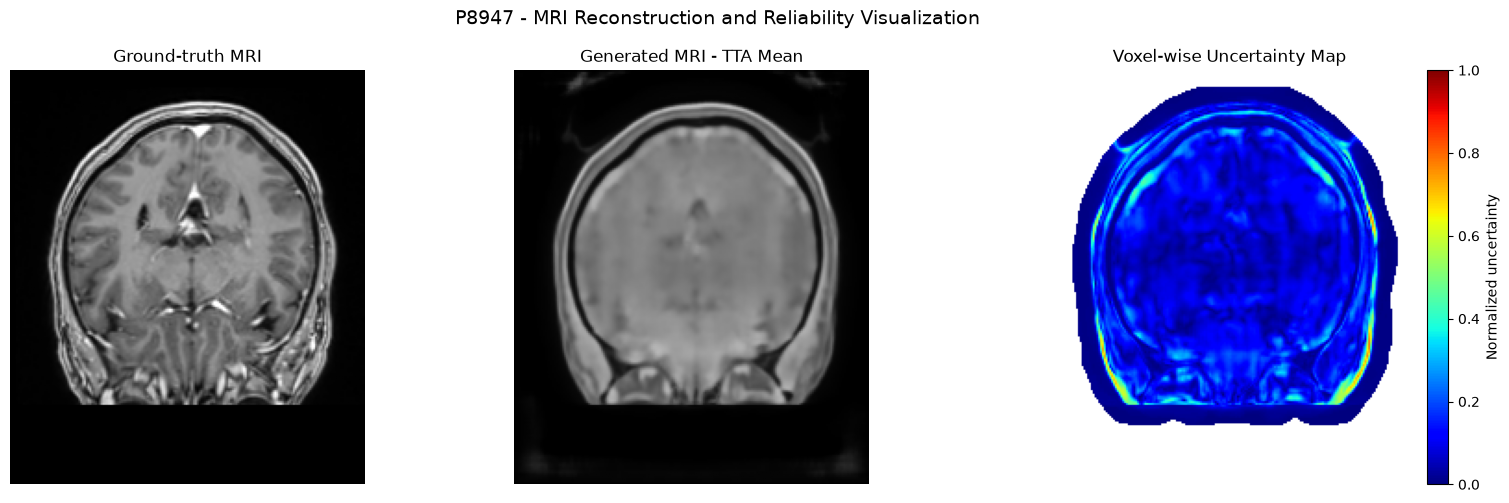

In [22]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Select patient
PATIENT_ID = "P8947"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# Load images
gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

pred = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_mean_mri.nii.gz")).dataobj,
    dtype=np.float32
)

unc = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_uncertainty.nii.gz")).dataobj,
    dtype=np.float32
)

mask = np.asarray(
    nib.load(str(VOLUME_DIR / "mask.nii.gz")).dataobj
)

# Normalize ground-truth MRI
gt = normalise_mri(gt, mask)

# Select middle axial slice
z = gt.shape[2] // 2

gt_slice = np.rot90(gt[:, :, z])
pred_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide pixels outside supplied mask
unc_display = np.where(mask_slice > 0, unc_slice, np.nan)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gt_slice, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground-truth MRI")

axes[1].imshow(pred_slice, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated MRI - TTA Mean")

im = axes[2].imshow(
    unc_display,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Voxel-wise Uncertainty Map")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalized uncertainty"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{PATIENT_ID} - MRI Reconstruction and Reliability Visualization",
    fontsize=14
)

plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


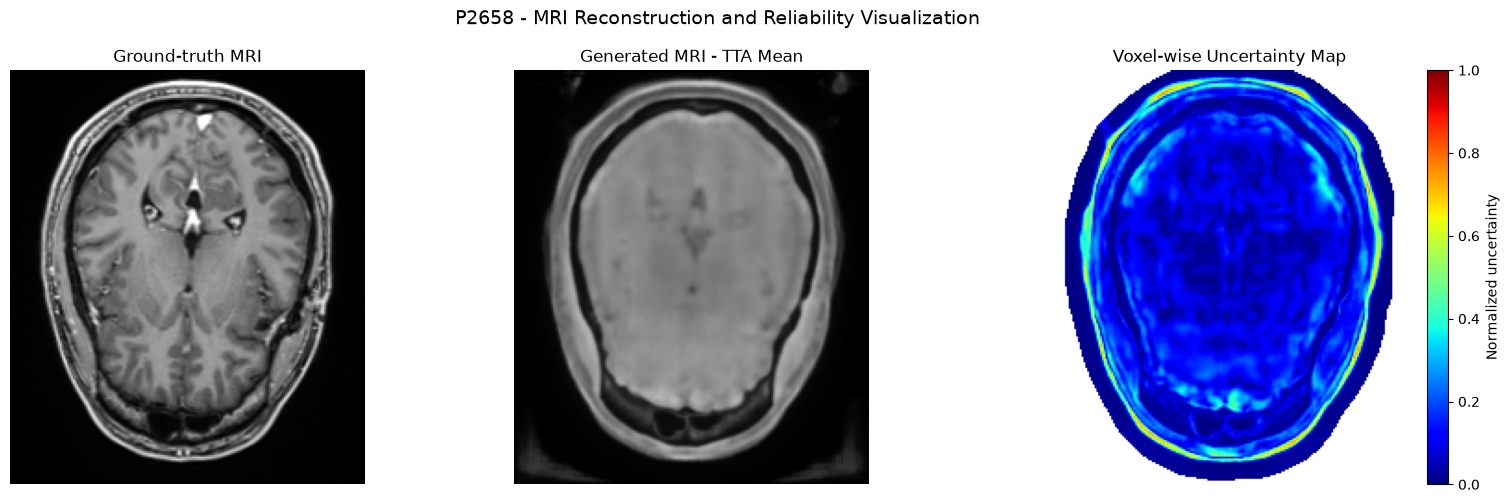

In [23]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Select patient
PATIENT_ID = "P2658"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# Load images
gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

pred = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_mean_mri.nii.gz")).dataobj,
    dtype=np.float32
)

unc = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_uncertainty.nii.gz")).dataobj,
    dtype=np.float32
)

mask = np.asarray(
    nib.load(str(VOLUME_DIR / "mask.nii.gz")).dataobj
)

# Normalize ground-truth MRI
gt = normalise_mri(gt, mask)

# Select middle axial slice
z = gt.shape[2] // 2

gt_slice = np.rot90(gt[:, :, z])
pred_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide pixels outside supplied mask
unc_display = np.where(mask_slice > 0, unc_slice, np.nan)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gt_slice, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground-truth MRI")

axes[1].imshow(pred_slice, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated MRI - TTA Mean")

im = axes[2].imshow(
    unc_display,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Voxel-wise Uncertainty Map")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalized uncertainty"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{PATIENT_ID} - MRI Reconstruction and Reliability Visualization",
    fontsize=14
)
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


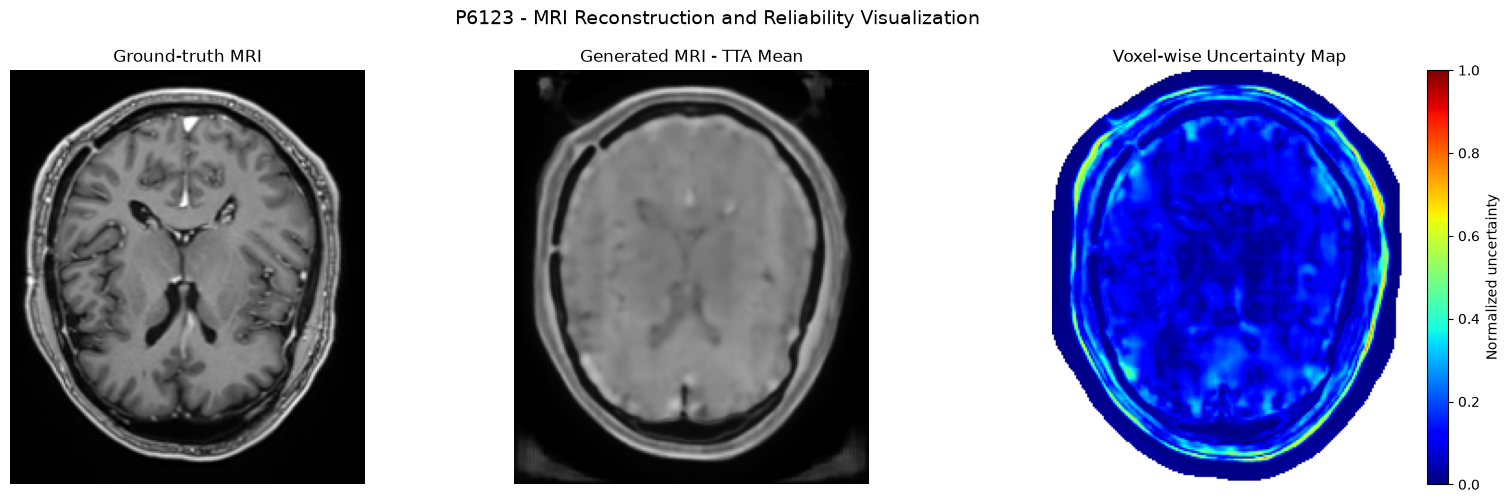

In [24]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Select patient
PATIENT_ID = "P6123"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# Load images
gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

pred = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_mean_mri.nii.gz")).dataobj,
    dtype=np.float32
)

unc = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_uncertainty.nii.gz")).dataobj,
    dtype=np.float32
)

mask = np.asarray(
    nib.load(str(VOLUME_DIR / "mask.nii.gz")).dataobj
)

# Normalize ground-truth MRI
gt = normalise_mri(gt, mask)

# Select middle axial slice
z = gt.shape[2] // 2

gt_slice = np.rot90(gt[:, :, z])
pred_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide pixels outside supplied mask
unc_display = np.where(mask_slice > 0, unc_slice, np.nan)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gt_slice, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground-truth MRI")

axes[1].imshow(pred_slice, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated MRI - TTA Mean")

im = axes[2].imshow(
    unc_display,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Voxel-wise Uncertainty Map")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalized uncertainty"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{PATIENT_ID} - MRI Reconstruction and Reliability Visualization",
    fontsize=14
)
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


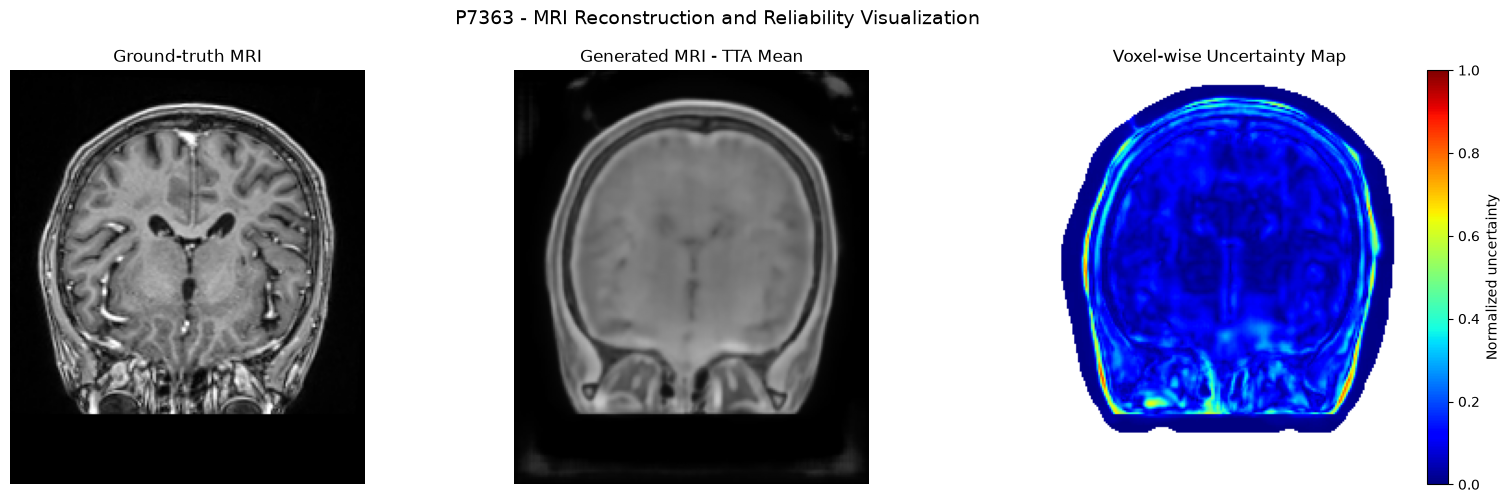

In [25]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Select patient
PATIENT_ID = "P7363"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# Load images
gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

pred = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_mean_mri.nii.gz")).dataobj,
    dtype=np.float32
)

unc = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_uncertainty.nii.gz")).dataobj,
    dtype=np.float32
)

mask = np.asarray(
    nib.load(str(VOLUME_DIR / "mask.nii.gz")).dataobj
)

# Normalize ground-truth MRI
gt = normalise_mri(gt, mask)

# Select middle axial slice
z = gt.shape[2] // 2

gt_slice = np.rot90(gt[:, :, z])
pred_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide pixels outside supplied mask
unc_display = np.where(mask_slice > 0, unc_slice, np.nan)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gt_slice, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground-truth MRI")

axes[1].imshow(pred_slice, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated MRI - TTA Mean")

im = axes[2].imshow(
    unc_display,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Voxel-wise Uncertainty Map")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalized uncertainty"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{PATIENT_ID} - MRI Reconstruction and Reliability Visualization",
    fontsize=14
)
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


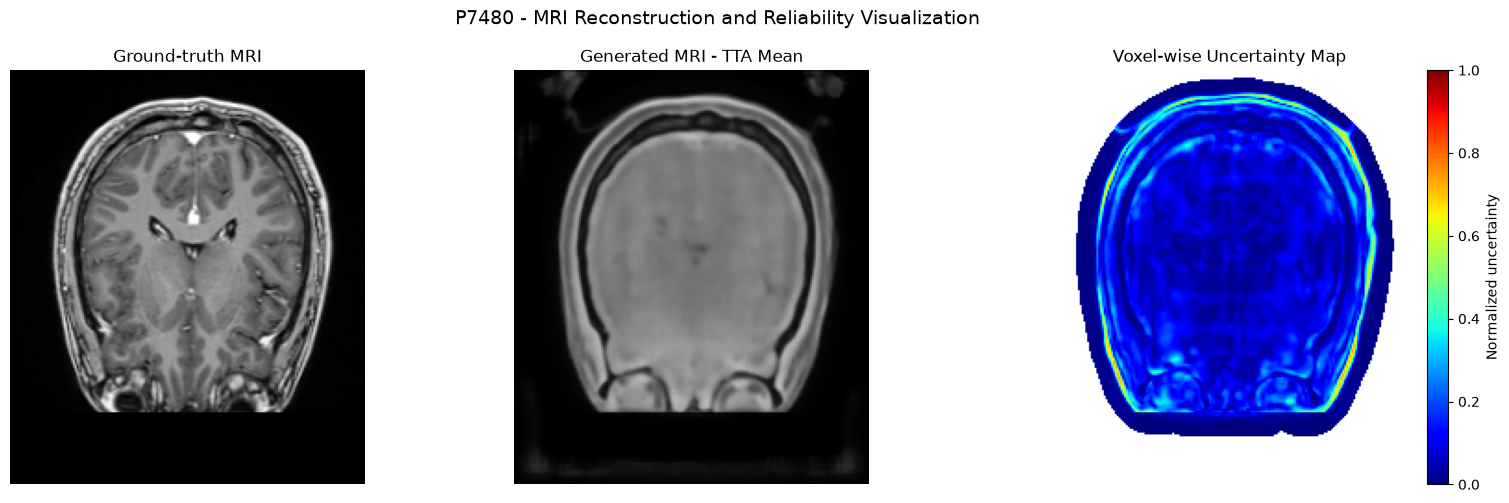

In [26]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Select patient
PATIENT_ID = "P7480"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# Load images
gt_img = nib.load(str(VOLUME_DIR / "mr.nii.gz"))
gt = np.asarray(gt_img.dataobj, dtype=np.float32)

pred = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_mean_mri.nii.gz")).dataobj,
    dtype=np.float32
)

unc = np.asarray(
    nib.load(str(OUTPUT_DIR / "tta_uncertainty.nii.gz")).dataobj,
    dtype=np.float32
)

mask = np.asarray(
    nib.load(str(VOLUME_DIR / "mask.nii.gz")).dataobj
)

# Normalize ground-truth MRI
gt = normalise_mri(gt, mask)

# Select middle axial slice
z = gt.shape[2] // 2

gt_slice = np.rot90(gt[:, :, z])
pred_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide pixels outside supplied mask
unc_display = np.where(mask_slice > 0, unc_slice, np.nan)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(gt_slice, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground-truth MRI")

axes[1].imshow(pred_slice, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Generated MRI - TTA Mean")

im = axes[2].imshow(
    unc_display,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[2].set_title("Voxel-wise Uncertainty Map")

fig.colorbar(
    im,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Normalized uncertainty"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{PATIENT_ID} - MRI Reconstruction and Reliability Visualization",
    fontsize=14
)
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


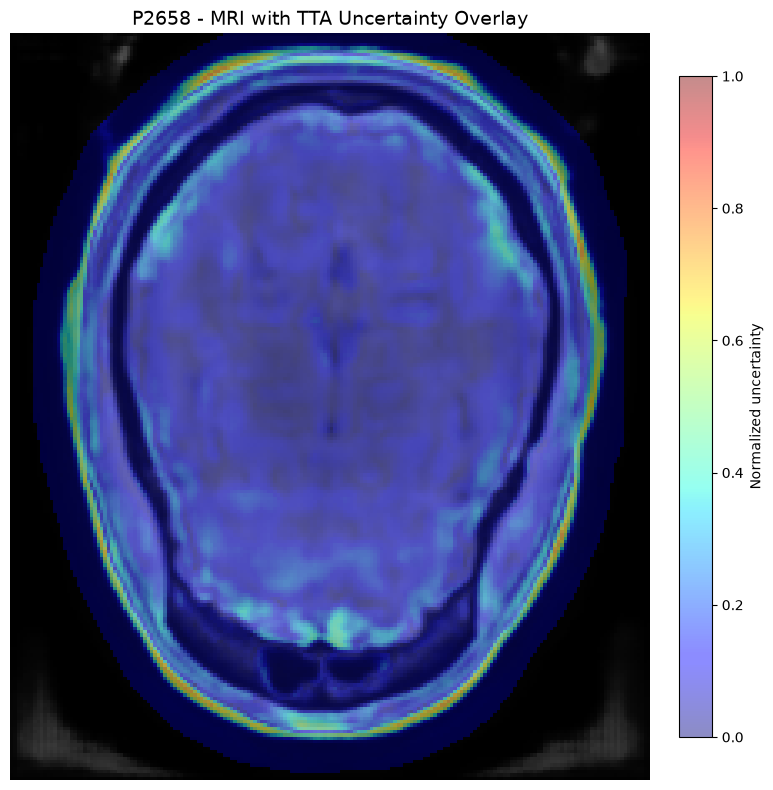

In [27]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# --------------------------------------------------
# Configuration
# --------------------------------------------------

PATIENT_ID = "P2658"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load generated MRI and uncertainty
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(pred_img.dataobj, dtype=np.float32)

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(unc_img.dataobj, dtype=np.float32)

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(mask_img.dataobj)

# --------------------------------------------------
# Verify alignment
# --------------------------------------------------

assert pred.shape == unc.shape == mask.shape
assert np.allclose(pred_img.affine, unc_img.affine)
assert np.allclose(pred_img.affine, mask_img.affine)

# --------------------------------------------------
# Select middle axial slice
# --------------------------------------------------

z = pred.shape[2] // 2

mri_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide uncertainty outside the supplied mask
unc_overlay = np.where(
    mask_slice > 0,
    unc_slice,
    np.nan
)

# --------------------------------------------------
# Create MRI + uncertainty overlay
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

# Background: generated MRI
ax.imshow(
    mri_slice,
    cmap="gray",
    vmin=0,
    vmax=1
)

# Foreground: uncertainty heatmap
im = ax.imshow(
    unc_overlay,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.45
)

ax.set_title(
    f"{PATIENT_ID} - MRI with TTA Uncertainty Overlay",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Normalized uncertainty")
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_uncertainty_overlay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


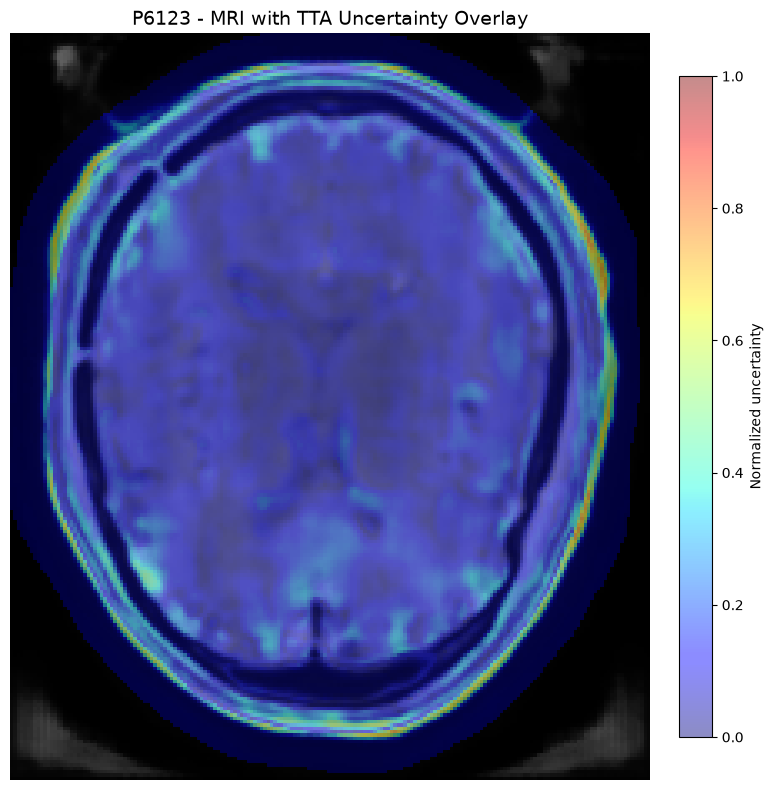

In [28]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# --------------------------------------------------
# Configuration
# --------------------------------------------------

PATIENT_ID = "P6123"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load generated MRI and uncertainty
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(pred_img.dataobj, dtype=np.float32)

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(unc_img.dataobj, dtype=np.float32)

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(mask_img.dataobj)

# --------------------------------------------------
# Verify alignment
# --------------------------------------------------

assert pred.shape == unc.shape == mask.shape
assert np.allclose(pred_img.affine, unc_img.affine)
assert np.allclose(pred_img.affine, mask_img.affine)

# --------------------------------------------------
# Select middle axial slice
# --------------------------------------------------

z = pred.shape[2] // 2

mri_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide uncertainty outside the supplied mask
unc_overlay = np.where(
    mask_slice > 0,
    unc_slice,
    np.nan
)

# --------------------------------------------------
# Create MRI + uncertainty overlay
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

# Background: generated MRI
ax.imshow(
    mri_slice,
    cmap="gray",
    vmin=0,
    vmax=1
)

# Foreground: uncertainty heatmap
im = ax.imshow(
    unc_overlay,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.45
)

ax.set_title(
    f"{PATIENT_ID} - MRI with TTA Uncertainty Overlay",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Normalized uncertainty")
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_uncertainty_overlay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


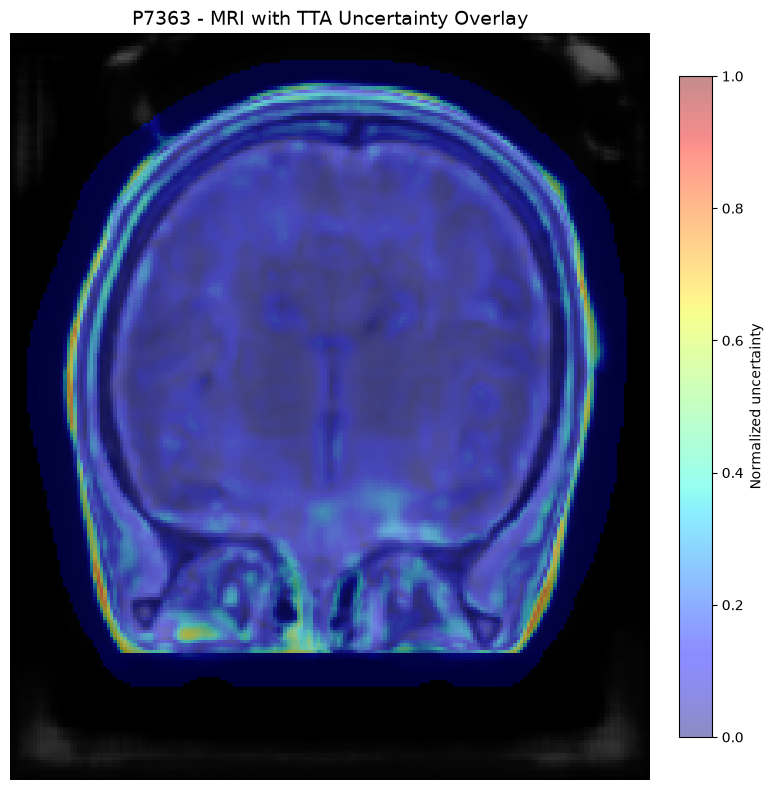

In [29]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# --------------------------------------------------
# Configuration
# --------------------------------------------------

PATIENT_ID = "P7363"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load generated MRI and uncertainty
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(pred_img.dataobj, dtype=np.float32)

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(unc_img.dataobj, dtype=np.float32)

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(mask_img.dataobj)

# --------------------------------------------------
# Verify alignment
# --------------------------------------------------

assert pred.shape == unc.shape == mask.shape
assert np.allclose(pred_img.affine, unc_img.affine)
assert np.allclose(pred_img.affine, mask_img.affine)

# --------------------------------------------------
# Select middle axial slice
# --------------------------------------------------

z = pred.shape[2] // 2

mri_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide uncertainty outside the supplied mask
unc_overlay = np.where(
    mask_slice > 0,
    unc_slice,
    np.nan
)

# --------------------------------------------------
# Create MRI + uncertainty overlay
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

# Background: generated MRI
ax.imshow(
    mri_slice,
    cmap="gray",
    vmin=0,
    vmax=1
)

# Foreground: uncertainty heatmap
im = ax.imshow(
    unc_overlay,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.45
)

ax.set_title(
    f"{PATIENT_ID} - MRI with TTA Uncertainty Overlay",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Normalized uncertainty")
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_uncertainty_overlay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


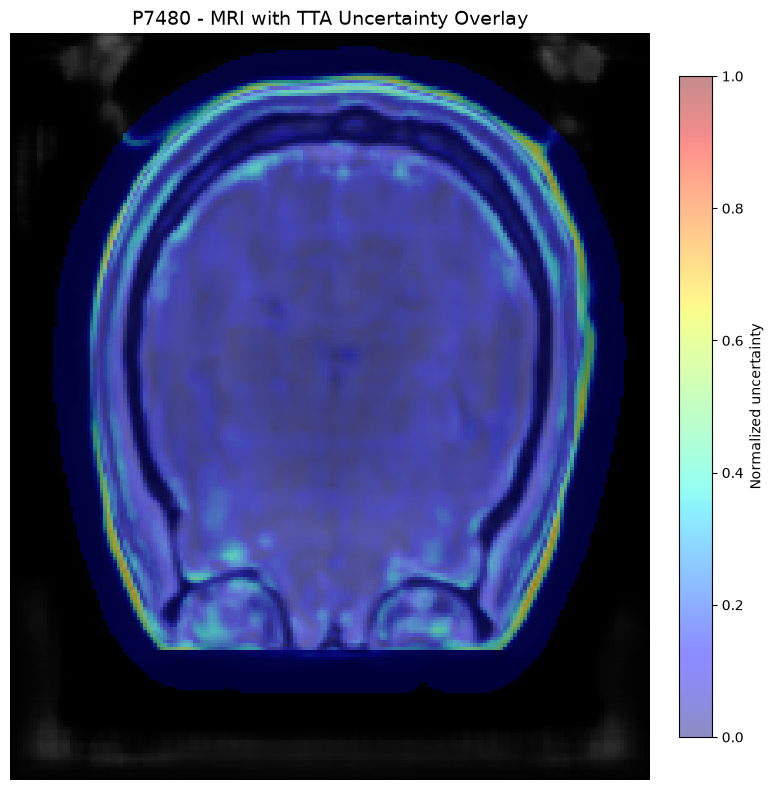

In [30]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# --------------------------------------------------
# Configuration
# --------------------------------------------------

PATIENT_ID = "P7480"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load generated MRI and uncertainty
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(pred_img.dataobj, dtype=np.float32)

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(unc_img.dataobj, dtype=np.float32)

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(mask_img.dataobj)

# --------------------------------------------------
# Verify alignment
# --------------------------------------------------

assert pred.shape == unc.shape == mask.shape
assert np.allclose(pred_img.affine, unc_img.affine)
assert np.allclose(pred_img.affine, mask_img.affine)

# --------------------------------------------------
# Select middle axial slice
# --------------------------------------------------

z = pred.shape[2] // 2

mri_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide uncertainty outside the supplied mask
unc_overlay = np.where(
    mask_slice > 0,
    unc_slice,
    np.nan
)

# --------------------------------------------------
# Create MRI + uncertainty overlay
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

# Background: generated MRI
ax.imshow(
    mri_slice,
    cmap="gray",
    vmin=0,
    vmax=1
)

# Foreground: uncertainty heatmap
im = ax.imshow(
    unc_overlay,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.45
)

ax.set_title(
    f"{PATIENT_ID} - MRI with TTA Uncertainty Overlay",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Normalized uncertainty")
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_uncertainty_overlay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


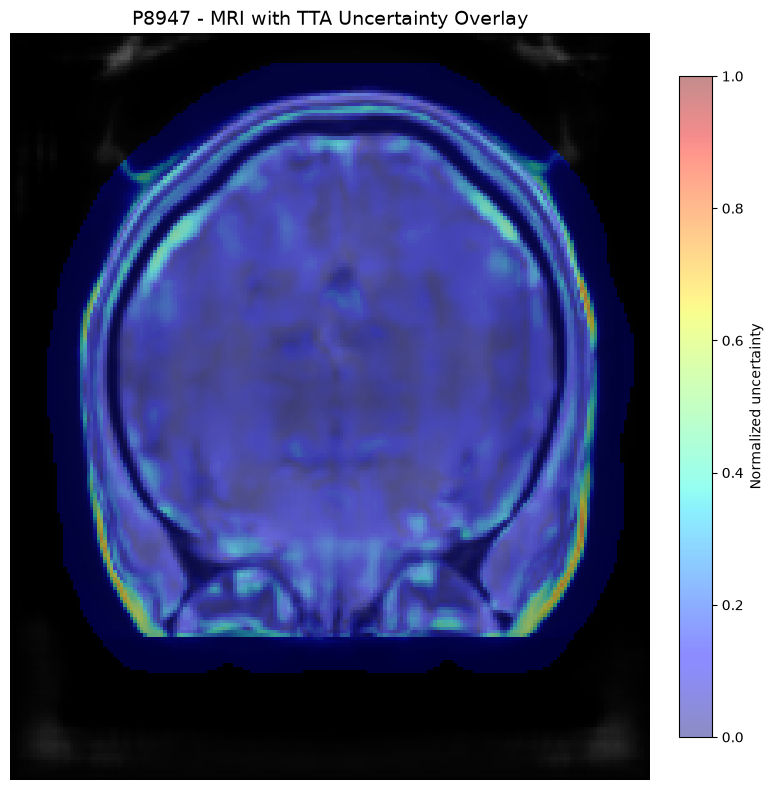

In [31]:

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# --------------------------------------------------
# Configuration
# --------------------------------------------------

PATIENT_ID = "P8947"

VOLUME_DIR = ROOT / "dataset" / "volumes" / PATIENT_ID
OUTPUT_DIR = ROOT / "outputs" / "reliability_test" / PATIENT_ID

# --------------------------------------------------
# Load generated MRI and uncertainty
# --------------------------------------------------

pred_img = nib.load(
    str(OUTPUT_DIR / "tta_mean_mri.nii.gz")
)

pred = np.asarray(pred_img.dataobj, dtype=np.float32)

unc_img = nib.load(
    str(OUTPUT_DIR / "tta_uncertainty.nii.gz")
)

unc = np.asarray(unc_img.dataobj, dtype=np.float32)

mask_img = nib.load(str(VOLUME_DIR / "mask.nii.gz"))

mask = np.asarray(mask_img.dataobj)

# --------------------------------------------------
# Verify alignment
# --------------------------------------------------

assert pred.shape == unc.shape == mask.shape
assert np.allclose(pred_img.affine, unc_img.affine)
assert np.allclose(pred_img.affine, mask_img.affine)

# --------------------------------------------------
# Select middle axial slice
# --------------------------------------------------

z = pred.shape[2] // 2

mri_slice = np.rot90(pred[:, :, z])
unc_slice = np.rot90(unc[:, :, z])
mask_slice = np.rot90(mask[:, :, z])

# Hide uncertainty outside the supplied mask
unc_overlay = np.where(
    mask_slice > 0,
    unc_slice,
    np.nan
)

# --------------------------------------------------
# Create MRI + uncertainty overlay
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 8))

# Background: generated MRI
ax.imshow(
    mri_slice,
    cmap="gray",
    vmin=0,
    vmax=1
)

# Foreground: uncertainty heatmap
im = ax.imshow(
    unc_overlay,
    cmap="jet",
    vmin=0,
    vmax=1,
    alpha=0.45
)

ax.set_title(
    f"{PATIENT_ID} - MRI with TTA Uncertainty Overlay",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Normalized uncertainty")
plt.savefig(
    OUTPUT_DIR / f"{PATIENT_ID}_MRI_uncertainty_overlay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()


In [21]:

from pathlib import Path
import csv
import numpy as np

# Project directory
ROOT = Path(r"D:\PS07_CT2MRI")

RESULT_DIR = ROOT / "results" / "reliability"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Results from the completed five-patient evaluation
results = [
    {
        "Patient": "P2658",
        "Masked_MAE": 0.10908,
        "Spearman_Correlation": 0.57988
    },
    {
        "Patient": "P6123",
        "Masked_MAE": 0.11643,
        "Spearman_Correlation": 0.56738
    },
    {
        "Patient": "P7363",
        "Masked_MAE": 0.11914,
        "Spearman_Correlation": 0.52960
    },
    {
        "Patient": "P7480",
        "Masked_MAE": 0.11521,
        "Spearman_Correlation": 0.56416
    },
    {
        "Patient": "P8947",
        "Masked_MAE": 0.1074395925,
        "Spearman_Correlation": 0.5930212682
    }
]

# Calculate patient-wise averages
average_mae = np.mean([r["Masked_MAE"] for r in results])
average_spearman = np.mean(
    [r["Spearman_Correlation"] for r in results]
)

# Save CSV
csv_path = RESULT_DIR / "reliability_metrics.csv"

with open(csv_path, "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=[
            "Patient",
            "Masked_MAE",
            "Spearman_Correlation"
        ]
    )

    writer.writeheader()
    writer.writerows(results)

    writer.writerow({
        "Patient": "AVERAGE",
        "Masked_MAE": average_mae,
        "Spearman_Correlation": average_spearman
    })

print("Reliability results saved successfully.")
print("Location:", csv_path)
print("Average Masked MAE:", average_mae)
print("Average Spearman:", average_spearman)


Reliability results saved successfully.
Location: D:\PS07_CT2MRI\results\reliability\reliability_metrics.csv
Average Masked MAE: 0.1134599185
Average Spearman: 0.56680825364
